# Jalon 2 - Kaggle, streaming et graphes

Lancer `run-jalon2.ps1` pour produire les preuves. Ce notebook lit les sorties enregistrees de DoorDash/Kaggle. Les utilisateurs et les droits sont des simulations.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, SVG
ROOT = Path('/workspace')
def read(name): return json.loads((ROOT / name).read_text(encoding='utf-8'))
manifest = read('data/generation_manifest.json')
display({k: manifest[k] for k in ['source', 'source_rows', 'events', 'restaurants', 'currency', 'simulated_fields']})

{'source': 'https://www.kaggle.com/datasets/dharun4772/doordash-eta-prediction',
 'source_rows': 197428,
 'events': 50000,
 'restaurants': 200,
 'currency': 'USD',
 'simulated_fields': ['customer_id',
  'courier_id',
  'tenant_id',
  'arrival_delay',
  'duplicates',
  'graph_access_policy']}

## Partie 4 - Source, transformations et sinks
Kafka alimente une table infinie. La console affiche les nouvelles lignes en mode append et le comptage ville/statut en mode complete. Bronze conserve le JSON et les offsets.

In [2]:
text = (ROOT / 'evidence/streaming-console.txt').read_text()
print(text[:6500])

+ docker compose exec -T jupyter python3 src/demo_streaming.py --run-id ...
+ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
-------------------------------------------
Batch: 0
-------------------------------------------
+--------+-------------+-----------+----+------+----------+-----------+-----------+----------+----------+---------+-----------------+----------+--------------+---------------------+----------------+------+--------+
|order_id|restaurant_id|customer_id|city|status|amount_usd|items_count|distance_km|courier_id|event_time|tenant_id|source_event_time|source_row|source_dataset|source_subtotal_cents|simulated_fields|run_id|scenario|
+--------+-------------+-----------+----+------+----------+-----------+-----------+----------+----------+---------+-----------------+----------+--------------+---------------------+----------------+------+--------+
+--------+-------------+-----------+----+------+----------+-----------+-----------+----------+----------+-----

## Partie 5 - Reprise et watermark
Le producteur envoie 2400 evenements pendant les 120 secondes d'arret. Le checkpoint restaure les offsets. La sonde en retard est conservee dans Bronze.

In [3]:
stream = read('results/jalon2/latest.json')
display(stream)
assert stream['status'] == 'PASS'
display(read('results/jalon2/streaming-metrics.json'))
print((ROOT/'results/jalon2/restart-experiment.jsonl').read_text())

{'run_id': 'run-kaggle-01',
 'status': 'PASS',
 'dataset_events': 3600,
 'sent_including_tests': 3623,
 'bronze_rows': 3623,
 'silver_rows': 3602,
 'injected_duplicates': 20,
 'late_probe_in_bronze': 1,
 'late_probe_in_silver': 0,
 'before_stop': 600,
 'after_restart': 3000,
 'producer_pause_test_seconds': 120,
 'no_loss_or_duplicates_on_recovery': True,
 'gold_matches_batch_oracle': True,
 'gold_rows': 36,
 'delta_versions': 2,
 'paths': {'bronze': 's3a://lake/bronze/orders_raw/run-kaggle-01',
  'silver': 's3a://lake/silver/orders_clean/run-kaggle-01',
  'gold': 's3a://lake/gold/kpi_city_10min/run-kaggle-01',
  'sliding': 's3a://lake/gold/cancellation_sliding/run-kaggle-01',
  'sessions': 's3a://lake/gold/courier_sessions/run-kaggle-01',
  'cp': 's3a://lake/checkpoints/run-kaggle-01'},
 'application_id': 'app-20261114110009-0003',
 'currency': 'USD',
 'replay_clock': 'one second per source event; original timestamp retained in source_event_time',
 'sliding_rows': 49,
 'session_rows': 

{'bronze': {'batches': 22,
  'nonempty_batches': 21,
  'max_trigger_ms': 11724,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0},
 'silver': {'batches': 25,
  'nonempty_batches': 19,
  'max_trigger_ms': 17882,
  'rows_dropped_by_watermark': 1,
  'duplicates_dropped': 20},
 'raw_console': {'batches': 6,
  'nonempty_batches': 4,
  'max_trigger_ms': 8999,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0},
 'counts_console': {'batches': 6,
  'nonempty_batches': 5,
  'max_trigger_ms': 15170,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0},
 'gold': {'batches': 3,
  'nonempty_batches': 1,
  'max_trigger_ms': 23234,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0},
 'sliding': {'batches': 3,
  'nonempty_batches': 1,
  'max_trigger_ms': 25148,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0},
 'sessions': {'batches': 3,
  'nonempty_batches': 1,
  'max_trigger_ms': 25279,
  'rows_dropped_by_watermark': 0,
  'duplicates_dropped': 0}}

{"phase": "before_stop", "utc": "2026-11-14T11:01:21.945172+00:00", "silver_rows": 600, "produced": 620, "seconds": 31.001727976999973}
{"phase": "consumer_stopped", "utc": "2026-11-14T11:01:22.221350+00:00", "producer_rate": 20, "planned_seconds": 120}
{"phase": "producer_during_stop", "utc": "2026-11-14T11:03:22.327972+00:00", "produced": 2400, "seconds": 120.00132721299997}
{"phase": "after_restart", "utc": "2026-11-14T11:03:53.342347+00:00", "silver_rows": 3000, "recovery_seconds": 30.924771575000022}
{"phase": "validation_passed", "utc": "2026-11-14T11:06:51.603964+00:00", "run_id": "run-kaggle-01", "status": "PASS", "dataset_events": 3600, "sent_including_tests": 3623, "bronze_rows": 3623, "silver_rows": 3602, "injected_duplicates": 20, "late_probe_in_bronze": 1, "late_probe_in_silver": 0, "before_stop": 600, "after_restart": 3000, "producer_pause_test_seconds": 120, "no_loss_or_duplicates_on_recovery": true, "gold_matches_batch_oracle": true, "gold_rows": 36, "delta_versions": 2

## Delta Lake et fenetres
Gold stocke les fenetres fermees. Le taux d'annulation utilise les statuts terminaux. Les sessions utilisent des livreurs simules.

In [4]:
display(read('results/jalon2/delta-history.json'))
display(read('results/jalon2/gold-sample.json')[:8])
display(read('results/window_contract_tests.json'))

[{'version': 1,
  'timestamp': '2026-11-14 11:06:05',
  'userId': None,
  'userName': None,
  'operation': 'STREAMING UPDATE',
  'operationParameters': {'epochId': '1',
   'outputMode': 'Append',
   'queryId': '4bf20850-572c-4f83-b36c-290f8f2a69ba'},
  'job': None,
  'notebook': None,
  'clusterId': None,
  'readVersion': 0,
  'isolationLevel': 'Serializable',
  'isBlindAppend': True,
  'operationMetrics': {'numOutputRows': '37',
   'numRemovedFiles': '0',
   'numAddedFiles': '4',
   'numOutputBytes': '10281'},
  'userMetadata': None,
  'engineInfo': 'Apache-Spark/3.5.6 Delta-Lake/3.3.2'},
 {'version': 0,
  'timestamp': '2026-11-14 11:05:53',
  'userId': None,
  'userName': None,
  'operation': 'STREAMING UPDATE',
  'operationParameters': {'epochId': '0',
   'outputMode': 'Append',
   'queryId': '4bf20850-572c-4f83-b36c-290f8f2a69ba'},
  'job': None,
  'notebook': None,
  'clusterId': None,
  'readVersion': None,
  'isolationLevel': 'Serializable',
  'isBlindAppend': True,
  'operation

[{'tenant_id': 'tenant-3',
  'city': 'Market-3',
  'window': {'start': '2026-11-14 12:00:00', 'end': '2026-11-14 12:10:00'},
  'orders_created': 2,
  'orders_delivered': 2,
  'revenue_usd': '31.24'},
 {'tenant_id': 'tenant-5',
  'city': 'Market-5',
  'window': {'start': '2026-11-14 12:30:00', 'end': '2026-11-14 12:40:00'},
  'orders_created': 10,
  'orders_delivered': 7,
  'revenue_usd': '161.15'},
 {'tenant_id': 'tenant-6',
  'city': 'Market-6',
  'window': {'start': '2026-11-14 12:50:00', 'end': '2026-11-14 13:00:00'},
  'orders_created': 15,
  'orders_delivered': 15,
  'revenue_usd': '285.90'},
 {'tenant_id': 'tenant-3',
  'city': 'Market-3',
  'window': {'start': '2026-11-14 12:20:00', 'end': '2026-11-14 12:30:00'},
  'orders_created': 0,
  'orders_delivered': 1,
  'revenue_usd': '77.23'},
 {'tenant_id': 'tenant-4',
  'city': 'Market-4',
  'window': {'start': '2026-11-14 12:50:00', 'end': '2026-11-14 13:00:00'},
  'orders_created': 104,
  'orders_delivered': 106,
  'revenue_usd': '

{'status': 'PASS',
 'source': 'explicit synthetic unit fixtures',
 'tumbling_revenue_usd': 120,
 'sliding_expected': {'11:55': [2, 1], '12:00': [3, 1], '12:05': [1, 0]},
 'sessions': 2,
 'cancellation_definition': 'CANCELLED / (DELIVERED + CANCELLED), by terminal-event time'}

## Partie 6 - GraphFrames et GraphX
Les restaurants Kaggle constituent les ressources. Les utilisateurs, roles et relations d'acces sont generes pour l'exercice. Comparer les degres du meme graphe.

In [5]:
gf = read('results/graphframes.json')
display({k:gf[k] for k in ['vertices','edges','tenants','motifs','inter_tenant_edges','negative_tests_rejected','degree_seconds','motif_seconds']})
display(read('results/graph_validation.json'))
display(gf['anomalies'][:8])

{'vertices': 290,
 'edges': 884,
 'tenants': [{'tenant_id': 'tenant-1',
   'vertices': 33,
   'edges': 86,
   'resources': 18},
  {'tenant_id': 'tenant-2', 'vertices': 106, 'edges': 378, 'resources': 91},
  {'tenant_id': 'tenant-3', 'vertices': 17, 'edges': 22, 'resources': 2},
  {'tenant_id': 'tenant-4', 'vertices': 91, 'edges': 318, 'resources': 76},
  {'tenant_id': 'tenant-5', 'vertices': 20, 'edges': 34, 'resources': 5},
  {'tenant_id': 'tenant-6', 'vertices': 23, 'edges': 46, 'resources': 8}],
 'motifs': 2800,
 'inter_tenant_edges': 0,
 'negative_tests_rejected': ['cross_tenant', 'duplicate_id', 'orphan_edge'],
 'degree_seconds': 6.65946768799995,
 'motif_seconds': 2.914014031999841}

{'status': 'PASS',
 'matched_vertices': 290,
 'degree_mismatches': 0,
 'components_match_independent_DFS': True,
 'components': 6,
 'tenants': 6,
 'pagerank_positive': True,
 'note': 'Degrees compared on identical directed multigraphs; connected components independently checked as weak connectivity.'}

[{'id': 'tenant-1:resource:DD-1-1145',
  'tenant_id': 'tenant-1',
  'rule': 'incoming CAN_ACCESS >= 3',
  'value': 3,
  'reason': 'Three roles can access this resource under the simulated policy.'},
 {'id': 'tenant-1:resource:DD-1-1469',
  'tenant_id': 'tenant-1',
  'rule': 'incoming CAN_ACCESS >= 3',
  'value': 3,
  'reason': 'Three roles can access this resource under the simulated policy.'},
 {'id': 'tenant-1:resource:DD-1-2438',
  'tenant_id': 'tenant-1',
  'rule': 'incoming CAN_ACCESS >= 3',
  'value': 3,
  'reason': 'Three roles can access this resource under the simulated policy.'},
 {'id': 'tenant-1:resource:DD-1-294',
  'tenant_id': 'tenant-1',
  'rule': 'incoming CAN_ACCESS >= 3',
  'value': 3,
  'reason': 'Three roles can access this resource under the simulated policy.'},
 {'id': 'tenant-1:resource:DD-1-3078',
  'tenant_id': 'tenant-1',
  'rule': 'incoming CAN_ACCESS >= 3',
  'value': 3,
  'reason': 'Three roles can access this resource under the simulated policy.'},
 {'id'

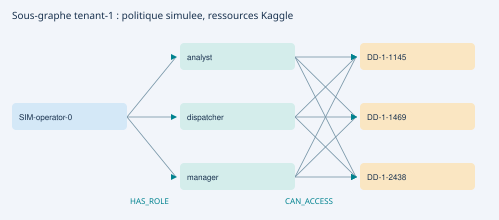

In [6]:
display(SVG(filename=str(ROOT/'evidence/graph-subgraph.svg')))

## Questions de soutenance
Ou Spark enregistre-t-il ses offsets ? Que mesure PageRank ?

Spark enregistre sa progression dans le checkpoint. PageRank decrit une centralite structurelle. La cle de dedoublonnage (order_id, status) ne borne pas automatiquement l'etat.